# 🔤 Dia 5 — Manipulação de Strings & Regex para Data Science / PLN

**Autor:** Gutemberg Rapôso · **Data:** 2026-10-18 · **Fase 1 — Python Basics (Dia 5/28)**

> Parte de uma jornada estruturada de 210 dias: *Junior → Senior Data Scientist | Aberto a Oportunidades Remotas*.

## 🎯 Objetivos de Aprendizagem

Ao final deste notebook, você será capaz de:

1. Usar os **métodos nativos de string** do Python (`upper`, `strip`, `split`, `join`, `replace`, `find`, f-strings...).
2. Escrever **expressões regulares** com o módulo `re` (`search`, `match`, `findall`, `finditer`, `sub`, `split`, `compile`, grupos e *named groups*).
3. Aplicar **operações vetorizadas de texto** no pandas via o acessor `.str`.
4. Construir um **pipeline de limpeza e tokenização** para PLN usando apenas a biblioteca padrão.
5. Analisar um **corpus de frases de ensino de inglês (níveis A1–C2 do CEFR)**: vocabulário, padrões gramaticais e estatísticas textuais.

## 🗺️ Roteiro

| Seção | Conteúdo |
|-------|----------|
| 1 | Métodos nativos de string |
| 2 | Expressões regulares com `re` |
| 3 | Operações de string no pandas |
| 4 | Limpeza de texto e tokenização para PLN |
| 5 | Projeto prático: corpus CEFR A1–C2 |
| 6 | Resumo e próximos passos |

## 🧠 Por que strings e regex importam tanto?

Estima-se que a maior parte dos dados corporativos seja **não estruturada** — e-mails, avaliações,
redações, transcrições. Antes de qualquer modelo de PLN, alguém precisa **limpar, normalizar e
extrair padrões** desse texto.

Do ponto de vista da **Linguística**, regex é uma forma de descrever *padrões formais* da língua:
sufixos morfológicos (`-ing`, `-ed`, `-tion`), contrações (`don't`, `I'm`), estruturas sintáticas
superficiais (`have/has + particípio`). Não substitui um *parser*, mas é a ferramenta mais rápida
para uma primeira análise de corpus.

In [1]:
# Only standard library + pandas/matplotlib/seaborn
import re
import string
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 100

print(f"pandas {pd.__version__} | seaborn {sns.__version__}")

pandas 2.2.3 | seaborn 0.13.2


---
## 1️⃣ Métodos Nativos de String

Strings em Python são **imutáveis**: todo método retorna uma *nova* string. Isso evita efeitos
colaterais, mas significa que precisamos reatribuir o resultado (`s = s.lower()`).

### 1.1 Caixa (case) e espaços em branco
`lower()`/`casefold()` são essenciais para normalização — `casefold()` é mais agressivo e lida
melhor com caracteres de outros idiomas (ex.: o alemão `ß` → `ss`).

In [2]:
raw = "   The Quick Brown Fox Jumps Over The Lazy Dog!   "

print(repr(raw.strip()))        # remove leading/trailing whitespace
print(repr(raw.lstrip()))       # left only
print(raw.strip().upper())
print(raw.strip().lower())
print(raw.strip().title())
print(raw.strip().swapcase())
print("Straße".lower(), "vs", "Straße".casefold())

'The Quick Brown Fox Jumps Over The Lazy Dog!'
'The Quick Brown Fox Jumps Over The Lazy Dog!   '
THE QUICK BROWN FOX JUMPS OVER THE LAZY DOG!
the quick brown fox jumps over the lazy dog!
The Quick Brown Fox Jumps Over The Lazy Dog!
tHE qUICK bROWN fOX jUMPS oVER tHE lAZY dOG!
straße vs strasse


### 1.2 Dividir e juntar: `split()` e `join()`
`split()` sem argumento divide por **qualquer sequência de espaços** — é a tokenização mais simples
possível. `join()` faz o caminho inverso e é muito mais eficiente que concatenar com `+` em loops.

In [3]:
sentence = "She has lived in London   for ten years."

tokens = sentence.split()                 # whitespace tokenization
print(tokens, len(tokens))

print(sentence.split(" "))                # NOTE: empty strings appear with repeated spaces
print("-".join(tokens))
print(" | ".join(word.upper() for word in tokens))

csv_line = "A1,beginner,greetings"
level, label, topic = csv_line.split(",")
print(level, label, topic)

['She', 'has', 'lived', 'in', 'London', 'for', 'ten', 'years.'] 8
['She', 'has', 'lived', 'in', 'London', '', '', 'for', 'ten', 'years.']
She-has-lived-in-London-for-ten-years.
SHE | HAS | LIVED | IN | LONDON | FOR | TEN | YEARS.
A1 beginner greetings


### 1.3 Buscar e contar: `find`, `index`, `count`, `startswith`, `endswith`, `in`
- `find()` retorna `-1` se não achar; `index()` lança `ValueError`.
- `startswith`/`endswith` aceitam **tuplas** — ótimo para checar vários prefixos/sufixos de uma vez.

In [4]:
text = "I have been studying English since I was a child."

print("find('English'):", text.find("English"))
print("find('French') :", text.find("French"))
print("count('I')     :", text.count("I"))
print("'study' in text:", "study" in text)
print(text.startswith("I have"), text.endswith("."))

words = ["running", "played", "happiness", "nation", "studied", "teacher"]
print("-ed/-ing words:", [w for w in words if w.endswith(("ed", "ing"))])
print("-ness/-tion    :", [w for w in words if w.endswith(("ness", "tion"))])

find('English'): 21
find('French') : -1
count('I')     : 2
'study' in text: True
True True
-ed/-ing words: ['running', 'played', 'studied']
-ness/-tion    : ['happiness', 'nation']


### 1.4 Substituir e testar o conteúdo
`replace()` faz substituições **literais** (sem padrões). Os métodos `is*()` são úteis para filtrar
tokens: `isalpha()`, `isdigit()`, `isupper()`, `istitle()`...

In [5]:
informal = "I'm gonna learn English cuz I wanna travel."
formal = (informal.replace("gonna", "going to")
                  .replace("wanna", "want to")
                  .replace("cuz", "because"))
print(formal)

for token in ["London", "2026", "B2", "hello", "NASA", "e-mail"]:
    print(f"{token:<8} alpha={token.isalpha()!s:<5} digit={token.isdigit()!s:<5} "
          f"alnum={token.isalnum()!s:<5} title={token.istitle()!s:<5} upper={token.isupper()}")

I'm going to learn English because I want to travel.
London   alpha=True  digit=False alnum=True  title=True  upper=False
2026     alpha=False digit=True  alnum=True  title=False upper=False
B2       alpha=False digit=False alnum=True  title=True  upper=True
hello    alpha=True  digit=False alnum=True  title=False upper=False
NASA     alpha=True  digit=False alnum=True  title=False upper=True
e-mail   alpha=False digit=False alnum=False title=False upper=False


### 1.5 Formatação: `format()` e f-strings
f-strings (Python 3.6+) são a forma mais legível e rápida. Elas aceitam **especificadores de formato**
(`:>10`, `:.2f`, `:,`, `:%`) e, desde o Python 3.8, o atalho de depuração `{var=}`.

In [6]:
level, n_sentences, avg_len = "B1", 10, 9.4567

print("Level {} has {} sentences (avg {:.1f} words)".format(level, n_sentences, avg_len))
print(f"Level {level} has {n_sentences} sentences (avg {avg_len:.1f} words)")
print(f"{level:>6}|{level:<6}|{level:^6}|")
print(f"Share of corpus: {n_sentences / 60:.1%}")
print(f"{avg_len=:.2f}")   # debugging shortcut

# string module constants are handy for cleaning
print(string.punctuation)
print(string.ascii_lowercase)

Level B1 has 10 sentences (avg 9.5 words)
Level B1 has 10 sentences (avg 9.5 words)
    B1|B1    |  B1  |
Share of corpus: 16.7%
avg_len=9.46
!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~
abcdefghijklmnopqrstuvwxyz


### 1.6 `str.translate()` — remoção de pontuação em alta velocidade
`str.maketrans` cria uma tabela de tradução caractere → caractere. Para remover pontuação, é
normalmente **mais rápido que regex**, pois opera em C, caractere a caractere.

In [7]:
punct_table = str.maketrans("", "", string.punctuation)

s = "Wow!!! Did you really say: 'English is easy'?"
print(s.translate(punct_table))

# Keep apostrophes (important for contractions like "don't")
keep_apostrophe = str.maketrans("", "", string.punctuation.replace("'", ""))
print(s.translate(keep_apostrophe))

Wow Did you really say English is easy
Wow Did you really say 'English is easy'


---
## 2️⃣ Expressões Regulares com o módulo `re`

Uma regex é uma **mini-linguagem para descrever padrões**. Principais elementos:

| Símbolo | Significado | Exemplo |
|---------|-------------|---------|
| `.` | qualquer caractere (exceto `\n`) | `c.t` → cat, cut |
| `\d`, `\w`, `\s` | dígito, caractere de palavra, espaço | `\d{4}` → 2026 |
| `\b` | fronteira de palavra | `\bcat\b` não casa com *catalog* |
| `*`, `+`, `?`, `{m,n}` | quantificadores | `colou?r` → color, colour |
| `[...]`, `[^...]` | classe / classe negada | `[aeiou]` |
| `^`, `$` | início / fim | `^The` |
| `( )`, `(?P<nome> )` | grupo / grupo nomeado | `(\w+)@(\w+)` |
| `\|` | alternância | `cat\|dog` |

> 💡 Sempre use **raw strings** (`r"..."`) para regex — assim `\b` não vira o caractere *backspace*.

### 2.1 `re.search` vs `re.match`
- `re.match` só tenta casar **no início** da string.
- `re.search` procura **em qualquer posição** e retorna o primeiro *match*.
Ambos retornam um objeto `Match` (ou `None`).

In [8]:
sentence = "Yesterday I visited my grandmother in 2019."

m1 = re.match(r"I visited", sentence)        # not at the start -> None
m2 = re.search(r"I visited", sentence)       # found anywhere
print("match :", m1)
print("search:", m2, "| span:", m2.span(), "| text:", m2.group())

year = re.search(r"\b\d{4}\b", sentence)
print("Year found:", year.group() if year else "none")

print(re.match(r"Yesterday", sentence) is not None)

match : None
search: <re.Match object; span=(10, 19), match='I visited'> | span: (10, 19) | text: I visited
Year found: 2019
True


### 2.2 `re.findall` e `re.finditer`
- `findall` retorna uma **lista de strings** (ou de tuplas, se houver grupos).
- `finditer` retorna um **iterador de objetos `Match`** — útil quando você precisa da posição.

In [9]:
text = ("She is reading a book while her brother is playing football. "
        "They were watching TV when the phone started ringing.")

ing_words = re.findall(r"\b\w+ing\b", text)
print("-ing forms:", ing_words)

for m in re.finditer(r"\b(is|are|was|were)\s+(\w+ing)\b", text):
    print(f"Progressive '{m.group(0)}' at {m.start()}-{m.end()} -> aux={m.group(1)}, verb={m.group(2)}")

-ing forms: ['reading', 'playing', 'watching', 'ringing']
Progressive 'is reading' at 4-14 -> aux=is, verb=reading
Progressive 'is playing' at 40-50 -> aux=is, verb=playing
Progressive 'were watching' at 66-79 -> aux=were, verb=watching


### 2.3 `re.sub` e `re.split`
`re.sub` substitui padrões — e aceita **referências a grupos** (`\1`) ou até uma **função** como
substituto. `re.split` divide usando um padrão (ex.: vários delimitadores de uma só vez).

In [10]:
messy = "Hello!!!   How    are you???  I'm   fine..."
print(re.sub(r"\s+", " ", messy))                 # collapse whitespace
print(re.sub(r"([!?.])\1+", r"\1", messy))        # collapse repeated punctuation

# Swap "First Last" -> "Last, First" using backreferences
print(re.sub(r"(\w+) (\w+)", r"\2, \1", "Gutemberg Raposo"))

# Function as replacement: uppercase every modal verb
modals = r"\b(can|could|may|might|must|should|would|will)\b"
print(re.sub(modals, lambda m: m.group().upper(), "You should study, and you will pass. You might win."))

# Split on several sentence delimiters at once
paragraph = "I love English. Do you? Yes! I study every day."
print(re.split(r"(?<=[.!?])\s+", paragraph))

Hello!!! How are you??? I'm fine...
Hello!   How    are you?  I'm   fine.
Raposo, Gutemberg
You SHOULD study, and you WILL pass. You MIGHT win.
['I love English.', 'Do you?', 'Yes!', 'I study every day.']


### 2.4 `re.compile` e flags
Compilar um padrão que será reutilizado muitas vezes deixa o código **mais legível** e evita
recompilação. Flags úteis: `re.IGNORECASE` (`re.I`), `re.MULTILINE` (`re.M`) e `re.VERBOSE` (`re.X`),
que permite escrever a regex em várias linhas com comentários.

In [11]:
# Verbose, documented pattern for English contractions
CONTRACTION = re.compile(
    r"""
    \b
    (?P<base>[A-Za-z]+)             # base word: I, you, do, can ...
    '                               # apostrophe
    (?P<clitic>m|s|re|ve|ll|d|t)    # contracted clitic
    \b
    """,
    re.VERBOSE | re.IGNORECASE,
)

sample = "I'm sure she's right, but they've said we'll see. Don't worry, it isn't late."
for m in CONTRACTION.finditer(sample):
    print(f"{m.group(0):<8} base={m.group('base'):<6} clitic={m.group('clitic')}")

print(type(CONTRACTION), CONTRACTION.pattern.count("\n"), "lines in pattern")

I'm      base=I      clitic=m
she's    base=she    clitic=s
they've  base=they   clitic=ve
we'll    base=we     clitic=ll
Don't    base=Don    clitic=t
isn't    base=isn    clitic=t
<class 're.Pattern'> 6 lines in pattern


### 2.5 Grupos de captura e *named groups*
Grupos `( )` capturam partes do *match*; grupos nomeados `(?P<nome>...)` deixam o código
autoexplicativo e permitem `groupdict()`. Grupos **não capturantes** `(?:...)` agrupam sem capturar.

Abaixo, extraímos metadados de linhas no formato de um registro de aula.

In [12]:
log_lines = [
    "2026-10-01 | student=ana.silva@school.edu | level=A2 | score=78",
    "2026-10-02 | student=joao_p@mail.com | level=B1 | score=85",
    "2026-10-03 | student=maria.r@school.edu | level=C1 | score=92",
]

LOG = re.compile(
    r"(?P<date>\d{4}-\d{2}-\d{2})\s*\|\s*"
    r"student=(?P<user>[\w.]+)@(?P<domain>[\w.]+)\s*\|\s*"
    r"level=(?P<level>[ABC][12])\s*\|\s*"
    r"score=(?P<score>\d+)"
)

records = [LOG.search(line).groupdict() for line in log_lines]
for r in records:
    print(r)

# Non-capturing group: match 'colour' or 'color' but capture only the suffix
print(re.findall(r"colo(?:u)?r(s|ful)?", "colours, colorful, color"))

{'date': '2026-10-01', 'user': 'ana.silva', 'domain': 'school.edu', 'level': 'A2', 'score': '78'}
{'date': '2026-10-02', 'user': 'joao_p', 'domain': 'mail.com', 'level': 'B1', 'score': '85'}
{'date': '2026-10-03', 'user': 'maria.r', 'domain': 'school.edu', 'level': 'C1', 'score': '92'}
['s', 'ful', '']


### 2.6 *Lookarounds* — olhar sem consumir
- `(?=...)` *lookahead* positivo · `(?!...)` *lookahead* negativo
- `(?<=...)` *lookbehind* positivo · `(?<!...)` *lookbehind* negativo

Útil, por exemplo, para encontrar palavras **seguidas de** algo sem incluí-lo no resultado.

In [13]:
text = "Mr. Smith paid $25 for the book and £30 for the dictionary in 2025."

print("Amounts after $ or £:", re.findall(r"(?<=[$£])\d+", text))
print("Capitalized words not after 'Mr. ':", re.findall(r"(?<!Mr\. )\b[A-Z][a-z]+\b", text))
print("Words followed by ' for':", re.findall(r"\b\w+(?= for\b)", text))

Amounts after $ or £: ['25', '30']
Capitalized words not after 'Mr. ': ['Mr']
Words followed by ' for': ['25', '30']


---
## 3️⃣ Operações de String no pandas (`.str`)

O acessor `.str` aplica métodos de string **vetorizados** a uma `Series` inteira, tratando `NaN`
automaticamente. A maioria aceita regex (`regex=True`). Vamos montar um pequeno DataFrame de
redações curtas de alunos (texto livre, como um professor coletaria em sala).

In [14]:
answers = pd.DataFrame({
    "student": ["Ana", "Bruno", "Carla", "Diego", "Elisa", "Fábio"],
    "answer": [
        "  I go to school by bus every day.  ",
        "Yesterday i goed to the park with my friends!!",
        "I have been living in Palmas since 2015.",
        "If I had more time, I would travel to Canada.",
        "She don't like coffee, she prefer tea.",
        None,
    ],
})
answers

,student,answer
0,Ana,I go to school by bus every day.
1,Bruno,Yesterday i goed to the park with my friends!!
2,Carla,I have been living in Palmas since 2015.
3,Diego,"If I had more time, I would travel to Canada."
4,Elisa,"She don't like coffee, she prefer tea."
5,Fábio,None


In [15]:
s = answers["answer"]

answers["clean"] = s.str.strip().str.lower()
answers["n_chars"] = s.str.len()
answers["n_words"] = s.str.split().str.len()
answers["has_year"] = s.str.contains(r"\b\d{4}\b", regex=True, na=False)
answers["upper_preview"] = s.str.strip().str.upper().str[:15]
answers[["student", "clean", "n_chars", "n_words", "has_year", "upper_preview"]]

,student,clean,n_chars,n_words,has_year,upper_preview
0,Ana,i go to school by bus every day.,36.0,8.0,False,I GO TO SCHOOL
1,Bruno,yesterday i goed to the park with my friends!!,46.0,9.0,False,YESTERDAY I GOE
2,Carla,i have been living in palmas since 2015.,40.0,8.0,True,I HAVE BEEN LIV
3,Diego,"if i had more time, i would travel to canada.",45.0,10.0,False,IF I HAD MORE T
4,Elisa,"she don't like coffee, she prefer tea.",38.0,7.0,False,SHE DON'T LIKE
5,Fábio,None,NaN,NaN,False,None


### 3.1 `str.extract` e `str.findall`
- `str.extract` retorna um **DataFrame** com uma coluna por grupo (nomes vêm dos *named groups*).
- `str.findall` retorna uma **lista** de todos os *matches* por linha.

In [16]:
answers[["first_word", "last_word"]] = s.str.extract(r"^\s*(?P<first>\w+).*?(?P<last>\w+)\W*$")
answers["capitalized"] = s.str.findall(r"\b[A-Z][a-z]+\b")
answers["pronouns"] = s.str.lower().str.findall(r"\b(?:i|you|he|she|we|they|my)\b")
answers[["student", "first_word", "last_word", "capitalized", "pronouns"]]

,student,first_word,last_word,capitalized,pronouns
0,Ana,I,day,[],[i]
1,Bruno,Yesterday,friends,[Yesterday],"[i, my]"
2,Carla,I,2015,[Palmas],[i]
3,Diego,If,Canada,"[If, Canada]","[i, i]"
4,Elisa,She,tea,[She],"[she, she]"
5,Fábio,NaN,NaN,None,None


### 3.2 `str.replace` com regex — correção automática simples
Como professor, um uso imediato é **sinalizar erros recorrentes** de aprendizes brasileiros
(ex.: *goed*, *she don't*, pronome *i* minúsculo). Isso é um esboço de *rule-based error detection*.

In [17]:
ERROR_RULES = {
    r"\bi\b": "I",                               # lowercase pronoun
    r"\bgoed\b": "went",                         # overregularized past
    r"\b(he|she|it) don't\b": r"\1 doesn't",     # 3rd-person agreement
    r"\b(he|she|it) prefer\b": r"\1 prefers",
    r"([!?.])\1+": r"\1",                         # repeated punctuation
}

corrected = s.str.strip()
for pattern, repl in ERROR_RULES.items():
    corrected = corrected.str.replace(pattern, repl, regex=True, flags=re.IGNORECASE)

answers["corrected"] = corrected
answers["was_changed"] = answers["corrected"] != s.str.strip()
answers[["student", "answer", "corrected", "was_changed"]]

,student,answer,corrected,was_changed
0,Ana,I go to school by bus every day.,I go to school by bus every day.,False
1,Bruno,Yesterday i goed to the park with my friends!!,Yesterday I went to the park with my friends!,True
2,Carla,I have been living in Palmas since 2015.,I have been living in Palmas since 2015.,False
3,Diego,"If I had more time, I would travel to Canada.","If I had more time, I would travel to Canada.",False
4,Elisa,"She don't like coffee, she prefer tea.","She doesn't like coffee, she prefers tea.",True
5,Fábio,None,None,True


In [18]:
# Split into columns and explode tokens to a long format (one row per token)
tokens_long = (answers.dropna(subset=["answer"])
                      .assign(token=lambda d: d["clean"].str.replace(r"[^\w\s']", "", regex=True).str.split())
                      .explode("token")[["student", "token"]])
print(tokens_long.shape)
tokens_long.head(10)

(42, 2)


,student,token
0,Ana,i
0,Ana,go
0,Ana,to
0,Ana,school
0,Ana,by
0,Ana,bus
0,Ana,every
0,Ana,day
1,Bruno,yesterday
1,Bruno,i


---
## 4️⃣ Limpeza de Texto e Tokenização para PLN

Um *pipeline* clássico de pré-processamento:

1. **Normalizar** caixa e espaços;
2. **Expandir contrações** (*don't* → *do not*) — decisão linguística importante;
3. **Remover pontuação / ruído** (URLs, e-mails, números, conforme o objetivo);
4. **Tokenizar**;
5. **Remover *stopwords*** (palavras funcionais).

> ⚠️ **Nota de linguista:** remover *stopwords* é ótimo para análise de tópicos, mas **péssimo** para
> análise gramatical — artigos, auxiliares e preposições são justamente o que diferencia um aluno A2 de
> um C1! Por isso o pipeline abaixo deixa essa etapa opcional.

In [19]:
CONTRACTIONS = {
    "won't": "will not", "can't": "cannot", "n't": " not", "'re": " are",
    "'s": " is", "'d": " would", "'ll": " will", "'ve": " have", "'m": " am",
}
CONTRACTION_RE = re.compile("|".join(map(re.escape, CONTRACTIONS)), re.IGNORECASE)

# Small hand-made English stopword list (no external libraries)
STOPWORDS = set("""
a an the and or but if of at by for with about to from in on into over under is am are was were be been
being have has had do does did i you he she it we they me him her us them my your his its our their this
that these those not no so than too very can will would should could may might must just
""".split())

def expand_contractions(text: str) -> str:
    """Expand English contractions using a longest-first dictionary lookup."""
    return CONTRACTION_RE.sub(lambda m: CONTRACTIONS[m.group(0).lower()], text)

def clean_text(text: str) -> str:
    """Lowercase, expand contractions, strip URLs/emails/digits/punctuation and extra spaces."""
    text = text.lower()
    text = expand_contractions(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text: str, remove_stopwords: bool = False) -> list[str]:
    """Clean and split text into word tokens, optionally removing stopwords."""
    tokens = clean_text(text).split()
    return [t for t in tokens if t not in STOPWORDS] if remove_stopwords else tokens

demo = "I can't believe it's 2026! Email me at teacher@school.edu or visit https://example.com — we'll practise."
print(expand_contractions(demo))
print(clean_text(demo))
print(tokenize(demo))
print(tokenize(demo, remove_stopwords=True))

I cannot believe it is 2026! Email me at teacher@school.edu or visit https://example.com — we will practise.
i cannot believe it is email me at or visit we will practise
['i', 'cannot', 'believe', 'it', 'is', 'email', 'me', 'at', 'or', 'visit', 'we', 'will', 'practise']
['cannot', 'believe', 'email', 'visit', 'practise']


### 4.1 Tokenização com regex vs `split()`
`split()` mantém pontuação grudada (`"day."`). Um tokenizador por regex pode **separar pontuação
como tokens próprios** e preservar contrações — mais próximo do que fazem bibliotecas como NLTK.

In [20]:
TOKEN_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?|\d+(?:\.\d+)?|[^\w\s]")

def regex_tokenize(text: str) -> list[str]:
    """Tokenize keeping contractions together and punctuation as separate tokens."""
    return TOKEN_RE.findall(text)

example = "Don't worry, it's only 3.5 km away. Let's go!"
print("split():", example.split())
print("regex  :", regex_tokenize(example))

def split_sentences(text: str) -> list[str]:
    """Naive sentence splitter that avoids breaking after common abbreviations."""
    return re.split(r"(?<!\bMr\.)(?<!\bMrs\.)(?<!\bDr\.)(?<=[.!?])\s+(?=[A-Z])", text.strip())

print(split_sentences("Dr. Brown teaches at Oxford. He loves grammar! Do you? Mr. Lee does."))

split(): ["Don't", 'worry,', "it's", 'only', '3.5', 'km', 'away.', "Let's", 'go!']
regex  : ["Don't", 'worry', ',', "it's", 'only', '3.5', 'km', 'away', '.', "Let's", 'go', '!']
['Dr. Brown teaches at Oxford.', 'He loves grammar!', 'Do you?', 'Mr. Lee does.']


---
## 5️⃣ Projeto Prático: Corpus de Frases de Ensino de Inglês (CEFR A1–C2)

### 5.1 O corpus
O **CEFR** (*Common European Framework of Reference for Languages*) organiza a proficiência em seis
níveis: **A1–A2** (básico), **B1–B2** (independente) e **C1–C2** (proficiente).

Abaixo está um corpus **criado manualmente** com 10 frases por nível, no estilo das que aparecem em
livros didáticos, cada uma rotulada com o **foco gramatical** principal. É um corpus *textual*
didático — nenhuma estatística foi inventada: todos os números a seguir são **calculados** a partir
destas frases.

**Hipótese (Linguística de Corpus):** frases de níveis mais altos devem apresentar maior
**comprimento**, maior **comprimento médio de palavra**, maior **diversidade lexical** e mais
**sufixos derivacionais** (*-tion*, *-ment*, *-ity*...).

In [21]:
corpus_data = {
    "A1": [
        ("My name is Anna and I am from Brazil.", "verb to be"),
        ("I have two brothers and one sister.", "have got / have"),
        ("She lives in a small house near the beach.", "present simple"),
        ("What time is it? It's seven o'clock.", "telling the time"),
        ("There is a big park in my city.", "there is / there are"),
        ("I like pizza, but I don't like fish.", "present simple negative"),
        ("He gets up at six every morning.", "present simple routines"),
        ("Can you swim? Yes, I can.", "modal can"),
        ("This is my favourite book.", "demonstratives"),
        ("We are students at the language school.", "verb to be"),
    ],
    "A2": [
        ("Last weekend I visited my grandparents in the countryside.", "past simple"),
        ("She was watching TV when the phone rang.", "past continuous"),
        ("I'm going to study medicine at university.", "going to future"),
        ("My brother is taller than me.", "comparatives"),
        ("We didn't go to the beach because it was raining.", "past simple negative"),
        ("You should drink more water every day.", "modal should"),
        ("Have you ever been to London?", "present perfect experience"),
        ("This is the most expensive restaurant in town.", "superlatives"),
        ("I usually walk to work, but today I'm taking the bus.", "present simple vs continuous"),
        ("There weren't many people at the concert.", "quantifiers"),
    ],
    "B1": [
        ("I have lived in this city since I was ten years old.", "present perfect since/for"),
        ("If it rains tomorrow, we will stay at home.", "first conditional"),
        ("The book that you lent me was really interesting.", "relative clauses"),
        ("She told me that she was feeling tired.", "reported speech"),
        ("I used to play football when I was a child.", "used to"),
        ("The bridge was built in the nineteenth century.", "passive voice"),
        ("You don't have to wear a uniform, but you mustn't be late.", "obligation modals"),
        ("I'm looking forward to seeing you next month.", "gerund after preposition"),
        ("Although it was cold, we decided to go for a walk.", "concession"),
        ("He has been working on the project all morning.", "present perfect continuous"),
    ],
    "B2": [
        ("If I had known about the traffic, I would have left earlier.", "third conditional"),
        ("By the time we arrived, the film had already started.", "past perfect"),
        ("I wish I could speak Japanese fluently.", "wish + past"),
        ("The new policy is expected to reduce unemployment significantly.", "passive reporting verbs"),
        ("She must have forgotten about the meeting.", "modals of deduction"),
        ("Not only did he apologise, but he also offered to pay for the damage.", "inversion"),
        ("I'd rather you didn't mention it to anyone.", "would rather"),
        ("The government's decision has caused widespread disappointment.", "nominalisation"),
        ("Having finished his homework, he went out with his friends.", "participle clauses"),
        ("This time next year, I will be living in Canada.", "future continuous"),
    ],
    "C1": [
        ("Had the authorities intervened sooner, the crisis might have been averted.", "inverted conditional"),
        ("It is widely acknowledged that climate change poses a significant threat to biodiversity.", "impersonal passive"),
        ("Despite considerable opposition, the legislation was eventually implemented.", "concession + passive"),
        ("What concerns me most is the lack of transparency in the decision-making process.", "cleft sentence"),
        ("The findings, which were published last year, have been called into question.", "non-defining relative clause"),
        ("Seldom have I encountered such a compelling argument.", "negative inversion"),
        ("Her reluctance to compromise ultimately undermined the negotiations.", "nominalisation"),
        ("Were it not for his determination, the expedition would have failed.", "inverted conditional"),
        ("The proliferation of misinformation online has profound implications for democracy.", "academic vocabulary"),
        ("It was not until the late twentieth century that the theory gained widespread acceptance.", "cleft sentence"),
    ],
    "C2": [
        ("The ramifications of the policy were not fully appreciated until long after its implementation.", "advanced nominalisation"),
        ("Notwithstanding the inherent limitations of the methodology, the study offers invaluable insights.", "formal concession"),
        ("So pervasive was the corruption that even the most scrupulous officials were implicated.", "so...that inversion"),
        ("Her eloquence notwithstanding, the candidate failed to allay the electorate's apprehensions.", "postpositive notwithstanding"),
        ("The ostensible simplicity of the poem belies its remarkable philosophical depth.", "advanced lexis"),
        ("Little did they realise the extent to which their actions would reverberate through history.", "negative inversion"),
        ("The commodification of education has engendered a profound epistemological crisis.", "academic register"),
        ("Insofar as the evidence permits, the hypothesis appears to be substantiated.", "hedging"),
        ("The juxtaposition of tradition and modernity is a recurrent motif in her fiction.", "literary analysis"),
        ("Had it not been for the unprecedented collaboration, the breakthrough would have been inconceivable.", "inverted third conditional"),
    ],
}

corpus = pd.DataFrame(
    [(level, sent, focus) for level, items in corpus_data.items() for sent, focus in items],
    columns=["level", "sentence", "grammar_focus"],
)
CEFR_ORDER = ["A1", "A2", "B1", "B2", "C1", "C2"]
corpus["level"] = pd.Categorical(corpus["level"], categories=CEFR_ORDER, ordered=True)

print(corpus.shape)
corpus.sample(6, random_state=42)

(60, 3)


,level,sentence,grammar_focus
0,A1,My name is Anna and I am from Brazil.,verb to be
5,A1,"I like pizza, but I don't like fish.",present simple negative
36,B2,I'd rather you didn't mention it to anyone.,would rather
45,C1,Seldom have I encountered such a compelling argument.,negative inversion
13,A2,My brother is taller than me.,comparatives
54,C2,The ostensible simplicity of the poem belies its remarkable philosophical de...,advanced lexis


### 5.2 Engenharia de *features* textuais
Calculamos, para cada frase, métricas clássicas de **complexidade linguística**:

- `n_words`, `n_chars` — extensão;
- `avg_word_len` — comprimento médio das palavras (*proxy* de sofisticação lexical);
- `ttr` — *Type-Token Ratio* (tipos únicos / total de tokens);
- `n_long_words` — palavras com 7+ letras;
- `n_commas` — *proxy* de subordinação/coordenação;
- `n_contractions` — marca de registro informal.

In [22]:
def text_features(sentence: str) -> pd.Series:
    """Compute surface-level linguistic complexity features for one sentence."""
    tokens = tokenize(sentence)
    n_tokens = len(tokens)
    return pd.Series({
        "n_words": n_tokens,
        "n_chars": len(sentence),
        "avg_word_len": round(sum(map(len, tokens)) / n_tokens, 2) if n_tokens else 0.0,
        "ttr": round(len(set(tokens)) / n_tokens, 3) if n_tokens else 0.0,
        "n_long_words": sum(len(t) >= 7 for t in tokens),
        "n_commas": sentence.count(","),
        "n_contractions": len(CONTRACTION.findall(sentence)),
    })

features = corpus["sentence"].apply(text_features)
int_cols = ["n_words", "n_chars", "n_long_words", "n_commas", "n_contractions"]
features[int_cols] = features[int_cols].astype(int)
corpus = pd.concat([corpus, features], axis=1)
corpus.head()

,level,sentence,grammar_focus,n_words,n_chars,avg_word_len,ttr,n_long_words,n_commas,n_contractions
0,A1,My name is Anna and I am from Brazil.,verb to be,9,37,3.11,1.000,0,0,0
1,A1,I have two brothers and one sister.,have got / have,7,35,4.00,1.000,1,0,0
2,A1,She lives in a small house near the beach.,present simple,9,42,3.67,1.000,0,0,0
3,A1,What time is it? It's seven o'clock.,telling the time,9,36,3.00,0.778,0,0,1
4,A1,There is a big park in my city.,there is / there are,8,31,2.88,1.000,0,0,0


In [23]:
level_stats = (corpus.groupby("level", observed=True)
                     [["n_words", "n_chars", "avg_word_len", "ttr", "n_long_words", "n_commas", "n_contractions"]]
                     .mean()
                     .round(2))
level_stats

,n_words,n_chars,avg_word_len,ttr,n_long_words,n_commas,n_contractions
level,,,,,,,
A1,7.6,33.9,3.48,0.94,0.5,0.2,0.2
A2,8.3,42.5,4.19,0.99,1.4,0.1,0.4
B1,9.9,47.3,3.85,0.94,1.4,0.3,0.3
B2,9.7,54.0,4.70,0.95,2.2,0.5,0.3
C1,10.9,75.8,6.08,0.98,3.9,0.5,0.0
C2,12.4,88.4,6.15,0.93,4.8,0.4,0.1


### 📊 Visualização 1 — Extensão das frases e comprimento médio das palavras por nível
Esperamos uma **tendência crescente** de A1 a C2 nas duas métricas.

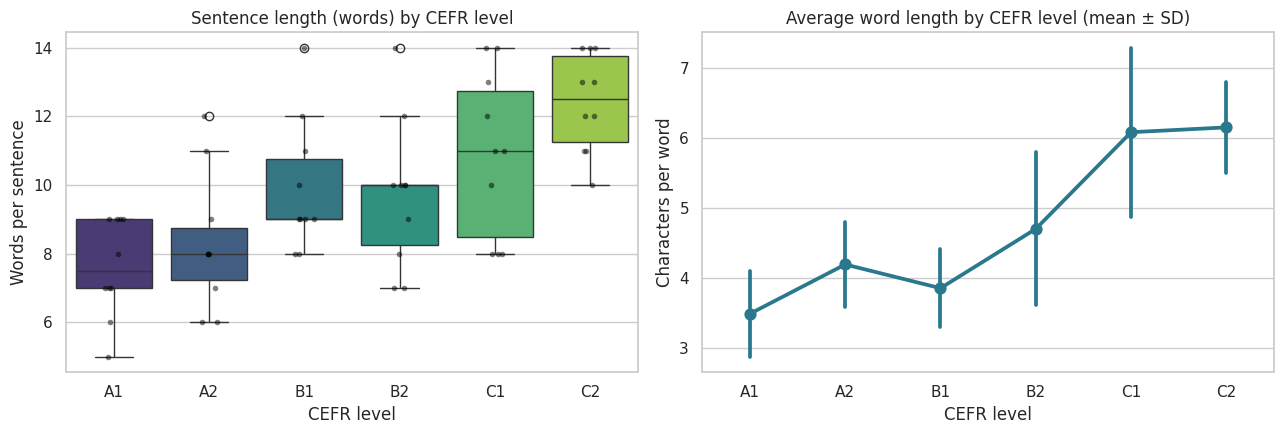

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=corpus, x="level", y="n_words", hue="level", palette="viridis", legend=False, ax=axes[0])
sns.stripplot(data=corpus, x="level", y="n_words", color="black", alpha=0.5, size=4, ax=axes[0])
axes[0].set_title("Sentence length (words) by CEFR level")
axes[0].set_xlabel("CEFR level"); axes[0].set_ylabel("Words per sentence")

sns.pointplot(data=corpus, x="level", y="avg_word_len", color="#2a788e", errorbar="sd", ax=axes[1])
axes[1].set_title("Average word length by CEFR level (mean ± SD)")
axes[1].set_xlabel("CEFR level"); axes[1].set_ylabel("Characters per word")

plt.tight_layout()
plt.show()

**🔎 Leitura:** os valores médios em `level_stats` (calculados acima) mostram uma **tendência geral**
de crescimento no número de palavras e no comprimento médio das palavras de A1 para C2 — com
oscilações entre níveis vizinhos (ex.: B1 × B2 têm extensão parecida, e A2 supera B1 em comprimento
de palavra) — coerente com a
progressão do CEFR, em que o aluno passa de frases curtas e vocabulário de alta frequência para
estruturas longas e léxico acadêmico/latinizado. Como o corpus é pequeno (10 frases/nível),
trata-se de uma **tendência descritiva**, não de uma conclusão estatística.

### 5.3 Extração de padrões gramaticais com regex
Agora usamos regex como um **"parser de superfície"** para detectar estruturas gramaticais. Cada
padrão é uma aproximação — vai gerar alguns falsos positivos/negativos, e discutir esses limites é
parte do trabalho do linguista computacional.

In [25]:
GRAMMAR_PATTERNS = {
    "present_perfect":   r"\b(?:have|has|'ve|'s)\s+(?:\w+ly\s+)?(?:been|\w+ed|known|done|gone|seen|made|lived|forgotten|encountered)\b",
    "past_perfect":      r"\b(?:had|'d)\s+(?:already\s+)?(?:been|\w+ed|known|started|gone|done)\b",
    "progressive":       r"\b(?:am|is|are|was|were|be|been|'m|'re)\s+\w+ing\b",
    "passive":           r"\b(?:is|are|was|were|be|been|being)\s+(?:\w+ly\s+)?(?:\w+ed|built|known|called|averted)\b",
    "modal_verb":        r"\b(?:can|could|may|might|must|should|would|will|shall|mustn't)\b",
    "conditional_if":    r"\bif\b",
    "inversion":         r"^(?:Had|Were|Seldom|Little|Not only|So \w+ was)\b",
    "relative_pronoun":  r"\b(?:who|which|that|whom|whose)\b",
    "nominal_suffix":    r"\b\w{3,}(?:tion|sion|ment|ness|ity|ance|ence)s?\b",
}

for name, pattern in GRAMMAR_PATTERNS.items():
    corpus[name] = corpus["sentence"].str.count(pattern, flags=re.IGNORECASE)

pattern_cols = list(GRAMMAR_PATTERNS)
corpus[["level", "sentence"] + pattern_cols].sample(5, random_state=7)

,level,sentence,present_perfect,past_perfect,progressive,passive,modal_verb,conditional_if,inversion,relative_pronoun,nominal_suffix
31,B2,"By the time we arrived, the film had already started.",0,1,0,0,0,0,0,0,0
20,B1,I have lived in this city since I was ten years old.,1,0,0,0,0,0,0,0,0
59,C2,"Had it not been for the unprecedented collaboration, the breakthrough would ...",1,0,0,0,1,0,1,0,1
17,A2,This is the most expensive restaurant in town.,0,0,0,0,0,0,0,0,0
10,A2,Last weekend I visited my grandparents in the countryside.,0,0,0,0,0,0,0,0,0


In [26]:
# Sanity check: inspect what each pattern actually matched in a few sentences
for name in ["present_perfect", "passive", "nominal_suffix", "inversion"]:
    hits = corpus["sentence"].str.findall(GRAMMAR_PATTERNS[name], flags=re.IGNORECASE)
    examples = [h for h in hits if h][:4]
    print(f"{name:<16} -> {examples}")

present_perfect  -> [['have lived'], ['has been'], ['have forgotten'], ['has caused']]
passive          -> [['was built'], ['is expected'], ['been averted'], ['is widely acknowledged']]
nominal_suffix   -> [['university'], ['unemployment'], ['mention'], ['government', 'decision', 'disappointment']]
inversion        -> [['Not only'], ['Had'], ['Seldom'], ['Were']]


### 📊 Visualização 2 — Mapa de calor: padrões gramaticais por nível
Mostramos a **média de ocorrências por frase** de cada padrão em cada nível.

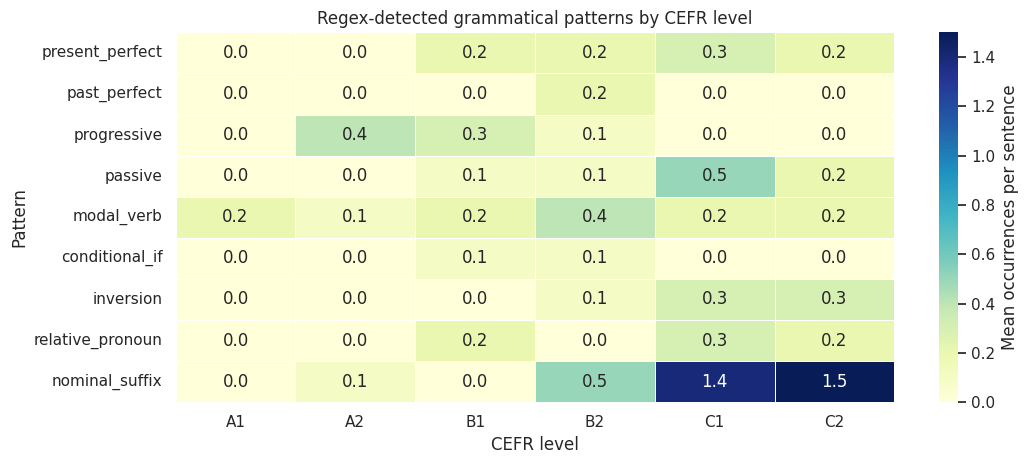

In [27]:
pattern_by_level = corpus.groupby("level", observed=True)[pattern_cols].mean()

plt.figure(figsize=(11, 4.8))
sns.heatmap(pattern_by_level.T, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "Mean occurrences per sentence"})
plt.title("Regex-detected grammatical patterns by CEFR level")
plt.xlabel("CEFR level"); plt.ylabel("Pattern")
plt.tight_layout()
plt.show()

**🔎 Leitura:** o mapa de calor permite visualizar a **progressão gramatical** do currículo:
formas **progressivas** aparecem sobretudo em A2–B1, enquanto **sufixos nominais**
(nominalização), **inversões** e **passivas** se concentram em B2–C2 — exatamente o que manuais de
*academic English* ensinam. Note também onde os padrões falham: perguntas como *Have you ever
been...?* escapam do padrão de *present perfect* (o sujeito fica entre auxiliar e particípio), e `'s`
pode ser *is*, *has* ou possessivo, lembrando que regex captura **forma**, não **função**.

### 5.4 Vocabulário: frequências com `Counter`
Construímos o vocabulário de cada nível (sem *stopwords*, para destacar palavras de conteúdo) e
medimos quantas palavras **novas** cada nível introduz em relação aos anteriores.

In [28]:
corpus["content_tokens"] = corpus["sentence"].apply(tokenize, remove_stopwords=True)

overall_freq = Counter(tok for toks in corpus["content_tokens"] for tok in toks)
print(f"Total content tokens: {sum(overall_freq.values())} | Vocabulary size: {len(overall_freq)}")
print("Top 15:", overall_freq.most_common(15))

vocab_by_level = {lvl: set().union(*corpus.loc[corpus["level"] == lvl, "content_tokens"]) for lvl in CEFR_ORDER}

seen, rows = set(), []
for lvl in CEFR_ORDER:
    vocab = vocab_by_level[lvl]
    new = vocab - seen
    rows.append({"level": lvl, "vocab_size": len(vocab), "new_words": len(new),
                 "pct_new": round(len(new) / len(vocab) * 100, 1),
                 "sample_new": ", ".join(sorted(new, key=len, reverse=True)[:5])})
    seen |= vocab

vocab_growth = pd.DataFrame(rows)
vocab_growth

Total content tokens: 296 | Vocabulary size: 266
Top 15: [('time', 3), ('most', 3), ('beach', 2), ('what', 2), ('there', 2), ('city', 2), ('like', 2), ('every', 2), ('morning', 2), ('book', 2), ('last', 2), ('when', 2), ('study', 2), ('go', 2), ('walk', 2)]


,level,vocab_size,new_words,pct_new,sample_new
0,A1,36,36,100.0,"favourite, students, language, brothers, morning"
1,A2,41,38,92.7,"grandparents, countryside, restaurant, university, expensive"
2,B1,43,37,86.0,"interesting, nineteenth, tomorrow, football, although"
3,B2,45,43,95.6,"disappointment, significantly, unemployment, widespread, government"
4,C1,61,53,86.9,"misinformation, determination, proliferation, considerable, negotiations"
5,C2,67,59,88.1,"notwithstanding, epistemological, commodification, implementation, juxtaposi..."


### 📊 Visualização 3 — Palavras mais frequentes e crescimento do vocabulário

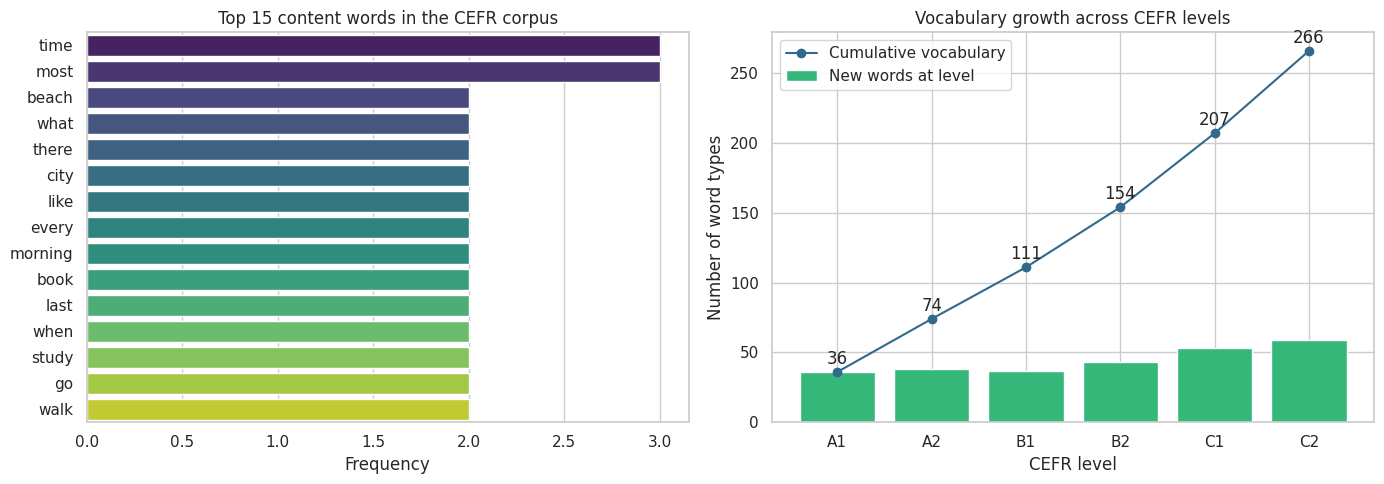

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_words = pd.DataFrame(overall_freq.most_common(15), columns=["word", "freq"])
sns.barplot(data=top_words, y="word", x="freq", hue="word", palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Top 15 content words in the CEFR corpus")
axes[0].set_xlabel("Frequency"); axes[0].set_ylabel("")

cumulative = vocab_growth["new_words"].cumsum()
axes[1].bar(vocab_growth["level"], vocab_growth["new_words"], color="#35b779", label="New words at level")
axes[1].plot(vocab_growth["level"], cumulative, marker="o", color="#31688e", label="Cumulative vocabulary")
for x, y in zip(vocab_growth["level"], cumulative):
    axes[1].annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 6), ha="center")
axes[1].set_title("Vocabulary growth across CEFR levels")
axes[1].set_xlabel("CEFR level"); axes[1].set_ylabel("Number of word types")
axes[1].legend()

plt.tight_layout()
plt.show()

### 5.5 Morfologia derivacional: sufixos por nível
Sufixos como *-tion*, *-ment*, *-ity*, *-ous* e *-ive* são marcas do vocabulário latino/acadêmico.
Vamos contar, por nível, a proporção de tokens que terminam em cada sufixo.

In [30]:
SUFFIX_RE = re.compile(r"(?P<stem>\w{3,}?)(?P<suffix>tion|sion|ment|ness|ity|ance|ence|ous|ive|al|ly)$")

def suffix_of(token: str) -> str | None:
    """Return the derivational suffix of a token, or None."""
    m = SUFFIX_RE.match(token)
    return m.group("suffix") if m else None

suffix_rows = [
    {"level": lvl, "token": tok, "suffix": suffix_of(tok)}
    for lvl, toks in zip(corpus["level"], corpus["sentence"].apply(tokenize))
    for tok in toks
]
suffix_df = pd.DataFrame(suffix_rows)
suffix_df["level"] = pd.Categorical(suffix_df["level"], categories=CEFR_ORDER, ordered=True)

suffix_rate = (suffix_df.assign(has_suffix=suffix_df["suffix"].notna())
                        .groupby("level", observed=True)["has_suffix"].mean()
                        .mul(100).round(1).rename("% tokens with derivational suffix"))
print(suffix_rate)

suffix_table = pd.crosstab(suffix_df["suffix"], suffix_df["level"])
suffix_table

level
A1     0.0
A2     3.6
B1     1.0
B2     7.2
C1    13.8
C2    13.7
Name: % tokens with derivational suffix, dtype: float64


level,A2,B1,B2,C1,C2
suffix,,,,,
al,0,0,0,0,2
ance,0,0,0,2,0
ence,0,0,0,0,2
ity,1,0,0,1,2
ive,1,0,0,0,1
ly,1,1,2,3,1
ment,0,0,3,1,0
ous,0,0,0,0,1
sion,0,0,1,1,0


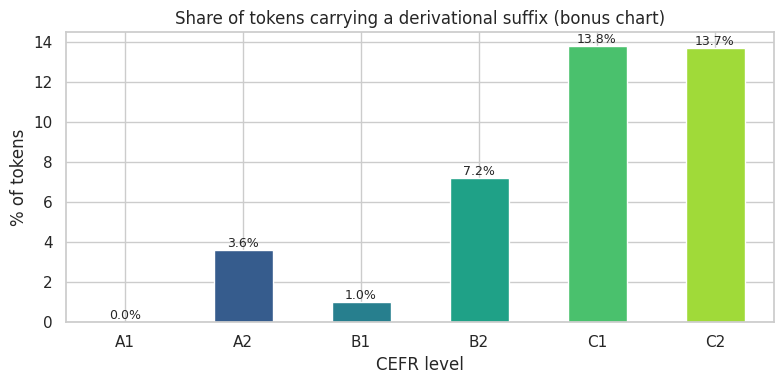

In [31]:
ax = suffix_rate.plot(kind="bar", color=sns.color_palette("viridis", 6), figsize=(8, 4), rot=0)
ax.set_title("Share of tokens carrying a derivational suffix (bonus chart)")
ax.set_xlabel("CEFR level"); ax.set_ylabel("% of tokens")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

### 5.6 Correlação entre as métricas de complexidade
Convertendo o nível CEFR em um número ordinal (A1=1 ... C2=6), verificamos quais *features*
acompanham mais de perto a progressão. É uma correlação de Spearman, apropriada para variáveis
ordinais.

In [32]:
corpus["level_num"] = corpus["level"].cat.codes + 1
metric_cols = ["n_words", "avg_word_len", "ttr", "n_long_words", "n_commas", "n_contractions", "nominal_suffix"]

spearman = (corpus[metric_cols + ["level_num"]]
            .corr(method="spearman")["level_num"]
            .drop("level_num")
            .sort_values(ascending=False)
            .round(3))
spearman.to_frame("spearman_rho_with_level")

,spearman_rho_with_level
n_long_words,0.815
avg_word_len,0.766
nominal_suffix,0.721
n_words,0.637
n_commas,0.226
ttr,-0.162
n_contractions,-0.207


### 5.7 Um mini "classificador" de nível baseado em regras
Para fechar o projeto, combinamos as *features* em um **escore de complexidade** simples e
estimamos o nível de frases novas. Não é *machine learning* (isso virá na Fase 4!), mas mostra como
features textuais extraídas com strings/regex já carregam sinal útil.

In [33]:
# Reference profile = mean feature values per level (computed from the corpus, not invented)
PROFILE_COLS = ["n_words", "avg_word_len", "n_long_words", "nominal_suffix"]
profiles = corpus.groupby("level", observed=True)[PROFILE_COLS].mean()
scale = corpus[PROFILE_COLS].std()

def estimate_level(sentence: str) -> str:
    """Return the CEFR level whose mean feature profile is closest (scaled Euclidean distance)."""
    feats = text_features(sentence)
    feats["nominal_suffix"] = len(re.findall(GRAMMAR_PATTERNS["nominal_suffix"], sentence, flags=re.I))
    vec = feats[PROFILE_COLS].astype(float)
    distances = (((profiles - vec) / scale) ** 2).sum(axis=1) ** 0.5
    return distances.idxmin()

new_sentences = [
    "I am hungry. Where is the kitchen?",
    "Last summer we travelled to Portugal and visited many museums.",
    "If I were you, I would apologise to her before the meeting.",
    "The unprecedented acceleration of urbanisation necessitates comprehensive infrastructural investment.",
]
for s in new_sentences:
    print(f"[{estimate_level(s)}] {s}")

[A1] I am hungry. Where is the kitchen?
[B2] Last summer we travelled to Portugal and visited many museums.
[B1] If I were you, I would apologise to her before the meeting.
[C2] The unprecedented acceleration of urbanisation necessitates comprehensive infrastructural investment.


In [34]:
# Resubstitution check on the corpus itself (optimistic, since profiles came from the same data)
corpus["predicted"] = corpus["sentence"].apply(estimate_level)
exact = (corpus["predicted"] == corpus["level"].astype(str)).mean()
within_one = (abs(pd.Categorical(corpus["predicted"], categories=CEFR_ORDER).codes
                  - corpus["level"].cat.codes) <= 1).mean()
print(f"Exact match: {exact:.1%} | Within ±1 level: {within_one:.1%}")
pd.crosstab(corpus["level"], corpus["predicted"], rownames=["true"], colnames=["predicted"])

Exact match: 55.0% | Within ±1 level: 93.3%


predicted,A1,A2,B1,B2,C1,C2
true,,,,,,
A1,9,1,0,0,0,0
A2,3,3,2,2,0,0
B1,0,4,5,1,0,0
B2,0,2,3,3,2,0
C1,0,0,0,2,5,3
C2,0,0,0,0,2,8


**🔎 Leitura crítica:** as taxas acima são calculadas sobre os **mesmos dados** usados para criar os
perfis (*resubstitution*), portanto são otimistas. Ainda assim, a matriz mostra que os erros tendem
a ocorrer entre **níveis vizinhos** — o que faz sentido linguisticamente, já que as fronteiras do
CEFR são graduais. Na Fase 4 vamos refazer isso com validação cruzada e modelos de verdade.

### 5.8 Exportando o corpus processado
Uma boa prática de portfólio: salvar o resultado em formato reutilizável. Aqui geramos a versão CSV
em memória (para não criar arquivos extras no repositório) e mostramos as primeiras linhas.

In [35]:
export_cols = ["level", "sentence", "grammar_focus", "n_words", "avg_word_len", "ttr", "nominal_suffix", "predicted"]
csv_text = corpus[export_cols].to_csv(index=False)
print(f"CSV size: {len(csv_text):,} characters | {csv_text.count(chr(10))} lines")
print("\n".join(csv_text.splitlines()[:4]))

CSV size: 5,861 characters | 61 lines
level,sentence,grammar_focus,n_words,avg_word_len,ttr,nominal_suffix,predicted
A1,My name is Anna and I am from Brazil.,verb to be,9,3.11,1.0,0,A1
A1,I have two brothers and one sister.,have got / have,7,4.0,1.0,0,A1
A1,She lives in a small house near the beach.,present simple,9,3.67,1.0,0,A1


---
## 6️⃣ Resumo & Principais Aprendizados

- **Strings são imutáveis**: métodos como `lower()`, `strip()`, `replace()` retornam novas strings.
- `split()`/`join()` são a base da tokenização; `str.translate()` remove pontuação de forma muito eficiente.
- **f-strings** com especificadores (`:.2f`, `:>8`, `:.1%`, `{var=}`) tornam relatórios legíveis.
- **Regex**: `search` (qualquer posição) × `match` (início); `findall` (strings) × `finditer` (objetos `Match`);
  `sub` aceita *backreferences* e funções; `compile` + `re.VERBOSE` = padrões documentados.
- **Named groups** (`(?P<nome>...)`) + `groupdict()` / `str.extract` transformam texto em colunas estruturadas.
- O acessor **`.str` do pandas** vetoriza tudo isso e lida com `NaN` (use `na=False` em `contains`).
- **Pré-processamento é uma decisão linguística**: remover *stopwords* ou expandir contrações muda a análise.
- No corpus CEFR, métricas simples (extensão, comprimento de palavra, nominalizações) acompanham a progressão de nível.

## ⚠️ Armadilhas Comuns

| Armadilha | Solução |
|-----------|---------|
| Esquecer o `r` em regex (`"\bword\b"`) | Sempre usar *raw strings* `r"..."` |
| Quantificadores gulosos (`.*`) capturando demais | Usar versão preguiçosa `.*?` |
| `str.contains` quebrando com `NaN` | Passar `na=False` |
| Caracteres especiais no padrão (`.`, `?`, `$`) | Usar `re.escape()` |
| Regex para tudo | Para remoção simples de pontuação, `translate()` é mais rápido |
| Confundir forma e função (`'s` = *is* ou possessivo?) | Validar com `findall` e, depois, usar POS tagging |

## 🚀 Próximos Passos
- Explorar **NLTK / spaCy** para tokenização, *POS tagging* e lematização (Fase 6).
- Usar métricas de legibilidade (Flesch-Kincaid) e listas de vocabulário (ex.: *Academic Word List*).
- Transformar o classificador por regras em um **modelo supervisionado** (Fase 4).

## 📚 Referências
- [Python docs — `re` module](https://docs.python.org/3/library/re.html)
- [Python docs — String methods](https://docs.python.org/3/library/stdtypes.html#string-methods)
- [pandas — Working with text data](https://pandas.pydata.org/docs/user_guide/text.html)
- [Council of Europe — CEFR descriptors](https://www.coe.int/en/web/common-european-framework-reference-languages)